In [1]:
# imports for analysis
import muspan as ms
import numpy as np
import pandas as pd
# imports to make plots pretty
import seaborn as sns
sns.set_theme(style='white',font_scale=2)
sns.set_style('ticks')
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
mpl.rcParams['figure.dpi'] = 150 # set the resolution of the figure
np.random.seed(42) # Fixed seed for reproducibility

import os

load in some domains

In [ ]:
directory = r"Z:\Amy\hpc_output\domains"

saved_domains = os.listdir(directory)

domains = []

for s_domain in saved_domains[-4:]:
    domain = ms.io.load_domain(os.path.join(directory,s_domain))
    domains.append(domain)

In [ ]:
available_networks = domain.networks
if "proximity_boundary" not in available_networks:
    print("Yes")
else:
    print("no")

In [ ]:

for domain in domains:
    qCells = ms.query.query(domain, ('Collection',), 'is', 'Cell centres') # Query the domain to get cell centres
    ms.networks.generate_network(
    domain,
    network_name='proximity_boundary',
    objects_as_nodes=qCells,
    network_type='Proximity',
    distance_weighted=True,
    min_edge_distance=0,
    max_edge_distance=15
    )

   

In [ ]:
# Define the clusters of interest
classes = ['CD8', 'CD8_Other', 'PDPN_CD8', 'PDPN_CD8_Other',
                        'FAP', 'FAP_PDGFRa', 'FAP_PDGFRa_aSMA', 'FAP_PDPN',
                   'FAP_PDPN_PDGFRa', 'FAP_PDPN_PDGFRa_aSMA', 'FAP_PDPN_aSMA', 'FAP_aSMA',
                   'PDGFRa', 'PDGFRa_aSMA', 'PDPN', 'PDPN_PDGFRa', 'PDPN_PDGFRa_aSMA', 'PDPN_aSMA','aSMA',
                    'panCK', 'panCK_Other','FAP_PDPN_panCK','FAP_panCK', 'PDPN_panCK', 'PDPN_panCK_Other', 'Other',  'unclassified detections']

neighbourhoods = [i for i in range(8)]

clusters_of_interest = neighbourhoods

In [ ]:
phenotype_colors = {
    'CD8' : 'cyan', 'CD8_Other': 'darkturquoise', 'PDPN_CD8' : 'cadetblue', 'PDPN_CD8_Other': 'darkcyan',
                        'FAP':'red', 'FAP_PDGFRa':'mediumvioletred', 'FAP_PDGFRa_aSMA':'violet', 'FAP_PDPN': 'darkviolet',
                   'FAP_PDPN_PDGFRa':'orchid', 'FAP_PDPN_PDGFRa_aSMA':'thistle', 'FAP_PDPN_aSMA':'mediumslateblue', 'FAP_aSMA': 'magenta',
                   'PDGFRa': 'yellow', 'PDGFRa_aSMA': 'khaki', 'PDPN': 'orange', 'PDPN_PDGFRa': 'gold', 'PDPN_PDGFRa_aSMA': 'goldenrod', 'PDPN_aSMA' : 'orangered','aSMA' : 'forestgreen',
                    'panCK' : 'whitesmoke', 'panCK_Other': 'lightgrey','FAP_PDPN_panCK': 'lavender','FAP_panCK': 'palevioletred', 'PDPN_panCK': 'peachpuff', 'PDPN_panCK_Other': 'wheat', 'Other': 'black',  'unclassified detections': 'grey'
}

neighbourhood_colors = {0:plt.cm.tab10(8), 
                        1:plt.cm.tab10(1), 
                        2:plt.cm.tab10(0), 
                        3:plt.cm.tab10(3),
                        4:plt.cm.tab10(2),  
                        5:plt.cm.tab10(4), 
                        6:plt.cm.tab10(6), 
                        7:plt.cm.tab10(9)}


# Update the domain with the new colors
#for domain in domains:
#   domain.update_colors(neighbourhood_colors, colors_to_update='labels', label_name='Neighbourhood ID - KNN 8')
#    ms.io.save_domain(domain, path_to_save= r"E:\Amy_muspan\muspanvenv\proximity\250714_COMB_domain_proximity", name_of_file= str(domain.name))


In [ ]:
# Import necessary libraries
import networkx as nx
import matplotlib.pyplot as plt


for domain in domains:
    labels, object_indices = ms.query.get_labels(domain, 'Neighbourhood ID - KNN 8')
    this_order_degree = {}
    total_contacts = np.zeros((len(clusters_of_interest), len(clusters_of_interest)))
    for idex, id in enumerate(clusters_of_interest):
    # Query the domain for the current cluster
        this_id_query = ms.query.query(domain, ('label', 'Neighbourhood ID - KNN 8'), 'is', id)
        
        try:
    # Generate k-hop neighbourhoods for the current cluster
            khop_neighbourhoods_prox = ms.networks.khop_neighbourhood(domain, network_name='proximity_boundary', source_objects=this_id_query, k=1)

    # Initialize a list to store the degrees
            these_degrees = []

    # Calculate the degree for each k-hop neighbourhood
            for k in khop_neighbourhoods_prox:
                these_degrees.append(len(khop_neighbourhoods_prox[k]))

    # Store the degrees in the dictionary
            this_order_degree[id] = these_degrees

         # Initialize an array to store the compositions
            these_compositions = np.zeros((len(khop_neighbourhoods_prox), len(clusters_of_interest)))
        # Calculate the composition for each k-hop neighbourhood
            for kid, k in enumerate(khop_neighbourhoods_prox):
                this_neighbourhood = khop_neighbourhoods_prox[k]
                for n in this_neighbourhood:
                    this_label_index = np.where(object_indices == n)[0][0]
                    if labels[this_label_index] in clusters_of_interest:
                        these_compositions[kid, clusters_of_interest.index(labels[this_label_index])] += 1
        # Calculate the average composition for the current cluster
            total_contacts[idex, :] = np.sum(these_compositions, axis=0)

        except:
            total_contacts[idex, :] = np.zeros((1, len(clusters_of_interest)))    
    #save the total_contacts array for each domain
    np.savetxt(os.path.join(r"E:\Amy_muspan\muspanvenv\proximity\250811_COMB_neighb_count_array", domain.name + "_array"),
                            total_contacts, fmt = '%d')



   


load in the count arrays and combine into giant array

In [2]:
#test_array = np.loadtxt(r"E:\Amy_muspan\muspanvenv\proximity\test_count_array\updated_B24-579 AB003 COMB Rx2 R2_Scan1_Stitched.csv_array", dtype = int)

#print(test_array)
array_dir = r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\output_KNN6\proximity\domain_arrays"

list_of_arrays = []

for filename in os.listdir(array_dir):
    cur_array = np.load(os.path.join(array_dir, filename))
    list_of_arrays.append(cur_array)

total_array = np.sum(list_of_arrays, axis=0)

print(total_array.shape)


(38, 38)


Remove contacts with itself

In [3]:
df = pd.read_csv(r"C:\Users\ewestlund\Documents\Python Projects\Roberto_MuSpAn\output_KNN6\proximity\proximity_labels_to_investigate.csv")
clusters_of_interest = df["Proximity Label"].tolist()


In [22]:
for i in range(len(clusters_of_interest)):
    total_array[i,i] = 0

print(total_array)

[[0.0000e+00 1.0000e+00 0.0000e+00 ... 2.0000e+00 2.2500e+02 5.2000e+01]
 [1.0000e+00 0.0000e+00 0.0000e+00 ... 1.0000e+00 1.3900e+02 5.1000e+01]
 [0.0000e+00 0.0000e+00 0.0000e+00 ... 2.0000e+00 3.8400e+02 2.2000e+01]
 ...
 [2.0000e+00 1.0000e+00 2.0000e+00 ... 0.0000e+00 4.2780e+03 1.6870e+03]
 [2.2500e+02 1.3900e+02 3.8400e+02 ... 4.2780e+03 0.0000e+00 1.0287e+04]
 [5.2000e+01 5.1000e+01 2.2000e+01 ... 1.6870e+03 1.0287e+04 0.0000e+00]]


In [23]:
norm_array = np.zeros((len(clusters_of_interest),len(clusters_of_interest)))

for i in range(len(clusters_of_interest)):
    norm_array[i,:] = total_array[i, :] / np.sum(total_array[i, :])


print(norm_array)



[[0.00000000e+00 5.58971492e-04 0.00000000e+00 ... 1.11794298e-03
  1.25768586e-01 2.90665176e-02]
 [6.77048070e-04 0.00000000e+00 0.00000000e+00 ... 6.77048070e-04
  9.41096818e-02 3.45294516e-02]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 6.07164542e-04
  1.16575592e-01 6.67880996e-03]
 ...
 [6.91682518e-05 3.45841259e-05 6.91682518e-05 ... 0.00000000e+00
  1.47950891e-01 5.83434204e-02]
 [6.72897196e-04 4.15700935e-04 1.14841121e-03 ... 1.27940187e-02
  0.00000000e+00 3.07648598e-02]
 [2.53455772e-04 2.48581623e-04 1.07231288e-04 ... 8.22269014e-03
  5.01403755e-02 0.00000000e+00]]


make a plot

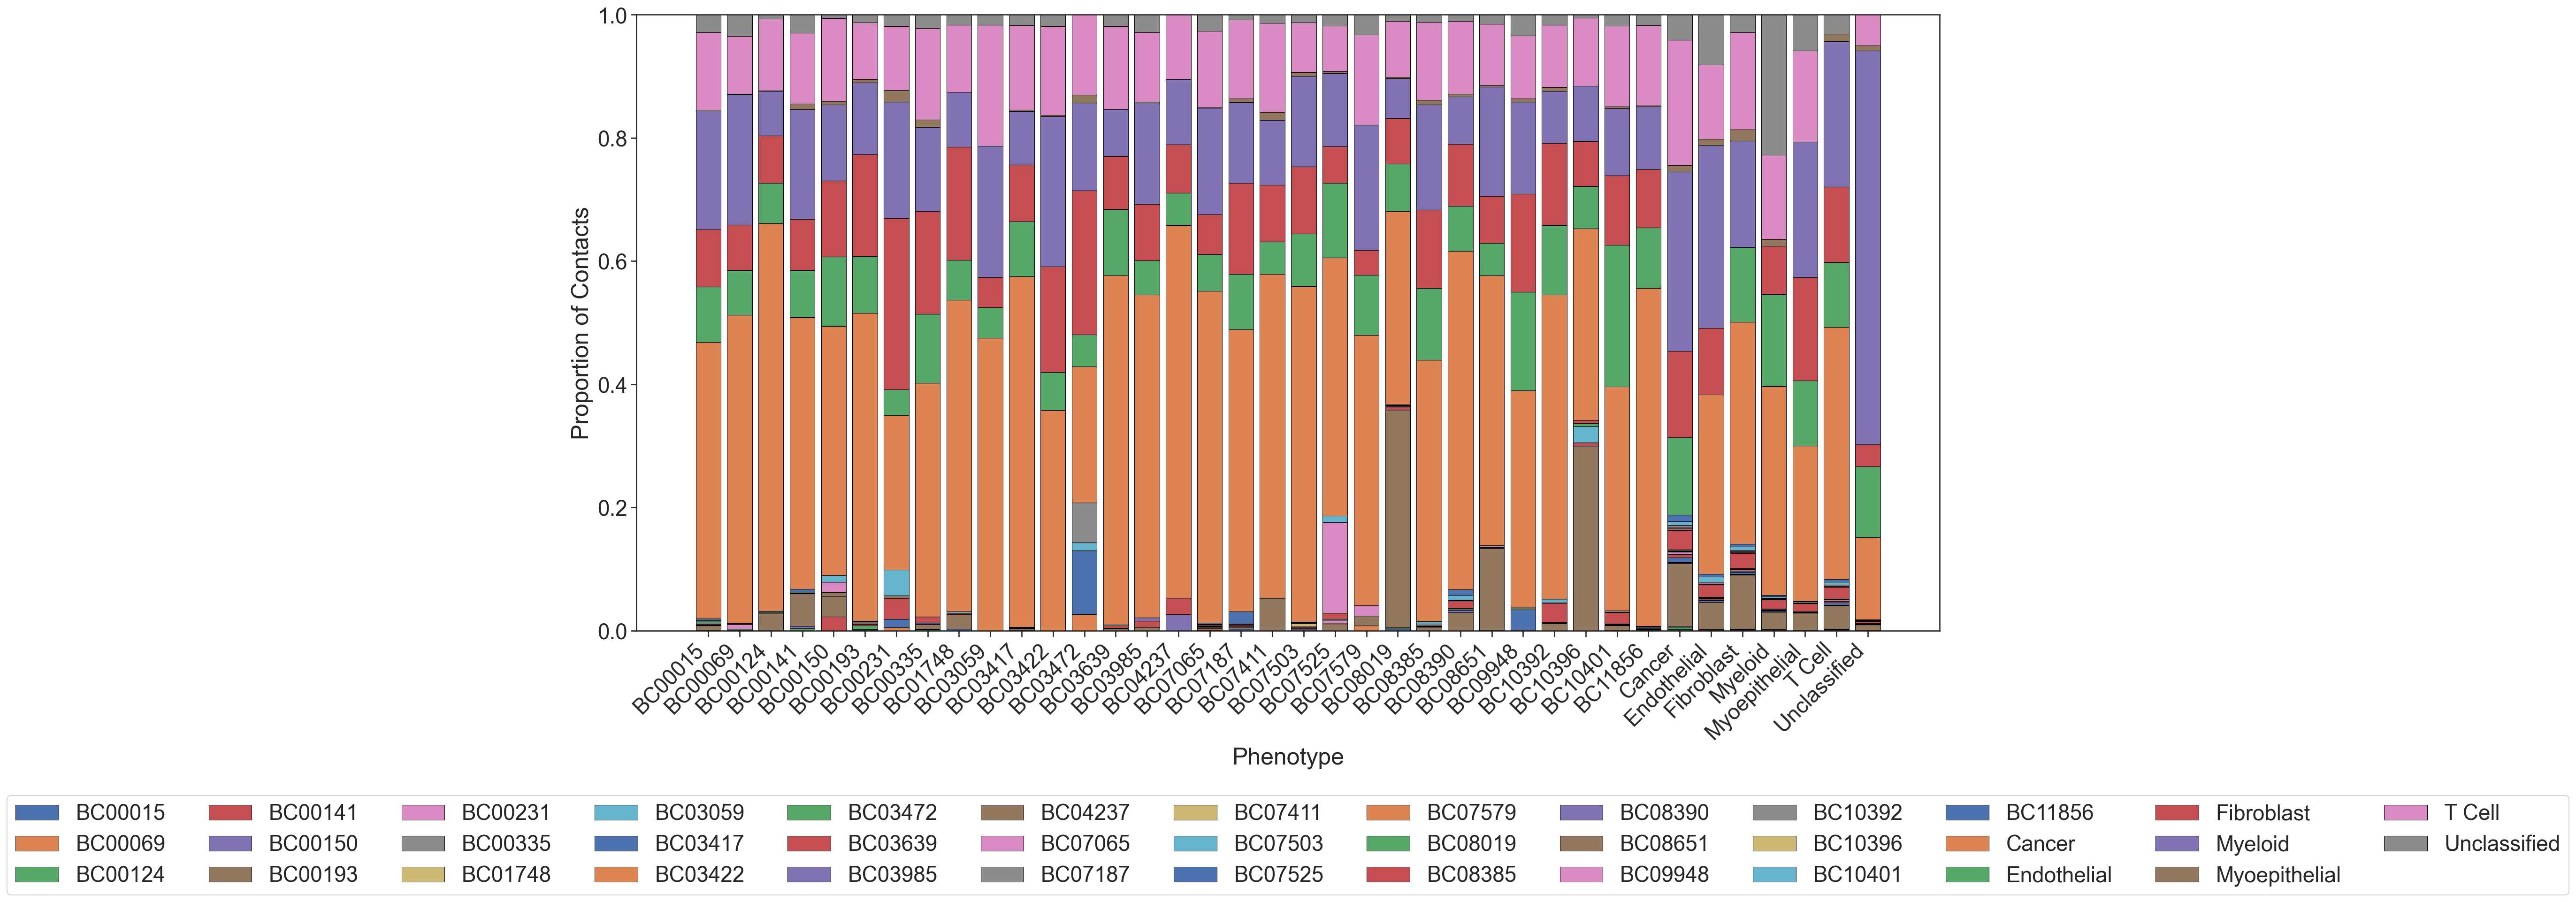

In [24]:
# Set the theme for seaborn plots
sns.set_theme(style='white', font_scale=2)
sns.set_style('ticks')

# Create a figure with two subplots

fig2, ax2 = plt.subplots(figsize=(20, 10))
fig2.tight_layout()


# Plot the stacked bar plot for each cluster
for i, cluster in enumerate(clusters_of_interest):
    ax2.bar(clusters_of_interest, norm_array[:, i], 
            label= cluster, bottom=np.sum(norm_array[:, :i], axis=1), 
            #color=phenotype_colors[cluster],
            edgecolor = "black",
            linewidth = 0.5)

# Set x-axis and y-axis labels for the stacked bar plot
ax2.set_xlabel('Phenotype')
ax2.set_ylabel('Proportion of Contacts')

# Set x-axis labels for the stacked bar plot
ax2.set_xticklabels(clusters_of_interest, rotation=45, ha='right')

# Add legend to the stacked bar plot
ax2.legend(bbox_to_anchor=(0.5, -0.25), loc='upper center', ncol=13)

# Show the plot
plt.show()

In [ ]:
# Set the theme for seaborn plots
sns.set_theme(style='white', font_scale=2)
sns.set_style('ticks')

# Create a figure with two subplots

fig2, ax2 = plt.subplots(figsize=(20, 10))
fig2.tight_layout()


# Plot the stacked bar plot for each cluster
for i, cluster in enumerate(clusters_of_interest):
    ax2.bar(clusters_of_interest, norm_array[:, i], 
            label= cluster, bottom=np.sum(norm_array[:, :i], axis=1), 
            color=neighbourhood_colors[cluster],
            edgecolor = "black",
            linewidth = 0.5)

# Set x-axis and y-axis labels for the stacked bar plot
ax2.set_xlabel('Neighbourhood')
ax2.set_ylabel('Proportion of Contacts')

# Set x-axis labels for the stacked bar plot
# Set x-axis labels for the stacked bar plot
ax2.set_xticklabels(["none", "0", "1", "2", "3", "4", "5", "6", "7"], rotation=0, ha='right', fontsize=24)

# Add legend to the stacked bar plot
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Show the plot
plt.show()